#Project 3: Smoke Season Tracker

###Research Question:
How many wildfire-smoke days did my city have each summer from 2023 to 2026, and what weather came with them?

##Slice:
One city, or a pair of cities to compare (for example a Minnesota city against a city closer
to the Canadian fires, or one on the West Coast).

##Cities:
Marshall, MN & Winnipeg, MB

Before starting, I will use the Open-Meteo Geocoding API to find both cities' coordinates. This is because the weather and air quality APIs require their latitude and longitude coordinates. The cell below finds the coordinates for Marshall, MN and Winnipeg Manitoba. I expect to the output to be both cities' coordinates alongside their timezone, country, and region information.

In [1]:
##Step 0.1: Finding the Coordinates of Marshall, Minnesota and Winnipeg, Manitoba
import requests

cities = [
    {"name": "Marshall, Minnesota", "countryCode": "US"},
    {"name": "Winnipeg, Manitoba", "countryCode": "CA"}
]

locations = {}

for city in cities:
    url = "https://geocoding-api.open-meteo.com/v1/search"

    params = {
        "name": city["name"],
        "count": 5,
        "countryCode": city["countryCode"],
        "language": "en",
        "format": "json"
    }

    try:
        response = requests.get(url, params=params, timeout=30)
        response.raise_for_status()
        data = response.json()

        results = data.get("results", [])

        if not results:
            print(f"No results found for {city['name']}")
            continue

        # Select the matching city
        match = results[0]

        locations[city["name"]] = {
            "latitude": match["latitude"],
            "longitude": match["longitude"],
            "country": match["country"],
            "admin1": match.get("admin1"),
            "timezone": match["timezone"]
        }

        print(f"\n{city['name']}")
        print(f"Country: {match['country']}")
        print(f"Region: {match.get('admin1')}")
        print(f"Latitude: {match['latitude']}")
        print(f"Longitude: {match['longitude']}")
        print(f"Timezone: {match['timezone']}")

    except requests.exceptions.RequestException as error:
        print(f"Request failed for {city['name']}: {error}")



Marshall, Minnesota
Country: United States
Region: Minnesota
Latitude: 44.4469
Longitude: -95.78835
Timezone: America/Chicago

Winnipeg, Manitoba
Country: Canada
Region: Manitoba
Latitude: 49.8844
Longitude: -97.14704
Timezone: America/Winnipeg


I now have the coordinates and geographically information required for the project.

The cell below tests Open-Meteo's air quality API for both cities during summer 2023. Hourly air quality measurements are requested to be later converted into daily averages and maximum values. A seperate API request is made for each city. The HTTP response and length of returned data lists is checked to ensure the information is usable. I should get hourly air quality data for both cities, along with variable lengths and missing values.

In [2]:
##Step 0.2: Test Air Quality API
import requests
import json
import os

os.makedirs("data/raw", exist_ok=True)

air_quality_url = "https://air-quality-api.open-meteo.com/v1/air-quality"

for city, location in locations.items():
    params = {
        "latitude": location["latitude"],
        "longitude": location["longitude"],
        "hourly": "pm2_5,us_aqi,us_aqi_pm2_5,aerosol_optical_depth",
        "start_date": "2023-06-01",
        "end_date": "2023-09-30",
        "timezone": location["timezone"]
    }

    try:
        response = requests.get(air_quality_url, params=params, timeout=60)
        print(f"\n{city} - Status code: {response.status_code}")
        response.raise_for_status()

        data = response.json()

        # Save the original API response
        filename = city.split(",")[0].lower() + "_air_quality_2023.json"
        with open(f"data/raw/{filename}", "w") as file:
            json.dump(data, file, indent=4)

        hourly = data["hourly"]
        lengths = {key: len(value) for key, value in hourly.items()}

        print("Response keys:", data.keys())
        print("Hourly record count:", len(hourly["time"]))
        print("Variable lengths:", lengths)
        print("Missing values:", {
            key: sum(value is None for value in values)
            for key, values in hourly.items()
            if key != "time"
        })

    except (requests.exceptions.RequestException, KeyError, ValueError) as error:
        print(f"Error retrieving data for {city}: {error}")



Marshall, Minnesota - Status code: 200
Response keys: dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])
Hourly record count: 2928
Variable lengths: {'time': 2928, 'pm2_5': 2928, 'us_aqi': 2928, 'us_aqi_pm2_5': 2928, 'aerosol_optical_depth': 2928}
Missing values: {'pm2_5': 0, 'us_aqi': 0, 'us_aqi_pm2_5': 0, 'aerosol_optical_depth': 0}

Winnipeg, Manitoba - Status code: 200
Response keys: dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])
Hourly record count: 2928
Variable lengths: {'time': 2928, 'pm2_5': 2928, 'us_aqi': 2928, 'us_aqi_pm2_5': 2928, 'aerosol_optical_depth': 2928}
Missing values: {'pm2_5': 0, 'us_aqi': 0, 'us_aqi_pm2_5': 0, 'aerosol_optical_depth': 0}


API test was successful. The air quality data for both cities was returned with their hourly record counts.

The cell below tests the Open-Meteo's historical data API by retrieving daily weather data for Marshall and Winnipeg from summer 2023. This data will be combined with air quality data as a shared key. The coordinates and timezone information from the previous step will be used. I expect daily weather measurements alongside precipitation, temperature, wind speed, and wind direction data.

In [3]:
##Step 0.3: Test Historical Weather API
import requests
import json
import time

weather_url = "https://archive-api.open-meteo.com/v1/archive"

for city, location in locations.items():
    params = {
        "latitude": location["latitude"],
        "longitude": location["longitude"],
        "start_date": "2023-06-01",
        "end_date": "2023-09-30",
        "daily": (
            "precipitation_sum,"
            "temperature_2m_max,"
            "wind_speed_10m_max,"
            "wind_direction_10m_dominant"
        ),
        "timezone": location["timezone"]
    }

    try:
        response = requests.get(weather_url, params=params, timeout=60)

        print(f"\n{city} - Status code: {response.status_code}")
        response.raise_for_status()

        data = response.json()

        # Save the original API response
        filename = city.split(",")[0].lower() + "_weather_2023.json"

        with open(f"data/raw/{filename}", "w") as file:
            json.dump(data, file, indent=4)

        daily = data["daily"]

        lengths = {
            key: len(value)
            for key, value in daily.items()
        }

        print("Response keys:", data.keys())
        print("Daily record count:", len(daily["time"]))
        print("Variable lengths:", lengths)

        print("Missing values:", {
            key: sum(value is None for value in values)
            for key, values in daily.items()
            if key != "time"
        })

    except (requests.exceptions.RequestException, KeyError, ValueError) as error:
        print(f"Error retrieving data for {city}: {error}")

    time.sleep(1)



Marshall, Minnesota - Status code: 200
Response keys: dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'daily_units', 'daily'])
Daily record count: 122
Variable lengths: {'time': 122, 'precipitation_sum': 122, 'temperature_2m_max': 122, 'wind_speed_10m_max': 122, 'wind_direction_10m_dominant': 122}
Missing values: {'precipitation_sum': 0, 'temperature_2m_max': 0, 'wind_speed_10m_max': 0, 'wind_direction_10m_dominant': 0}

Winnipeg, Manitoba - Status code: 200
Response keys: dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'daily_units', 'daily'])
Daily record count: 122
Variable lengths: {'time': 122, 'precipitation_sum': 122, 'temperature_2m_max': 122, 'wind_speed_10m_max': 122, 'wind_direction_10m_dominant': 122}
Missing values: {'precipitation_sum': 0, 'temperature_2m_max': 0, 'wind_speed_10m_max': 0, 'wind_direction_10m_dom

122 daily weather measurements were retrieved, with 122 measurements for each of the four weather measurements, and 0 missing values.

After successfully testing the APIs, the full data will now be extracted across the summers of 2023 to 2026. The cell below will retrieve the air quality data for Marshall and Winnipeg, including their coordinates, timezones, date range, and four air quality variables. The original responses will be saved as JSON files to data/raw/. I expect thousands of records per city for each summer.

In [4]:
#Step 1.1: Extract Full Air Quality Data
import time
import os

years = [2023, 2024, 2025, 2026]

air_quality_url = "https://air-quality-api.open-meteo.com/v1/air-quality"

for city, location in locations.items():
    city_name = city.split(",")[0].lower()

    for year in years:
        params = {
            "latitude": location["latitude"],
            "longitude": location["longitude"],
            "hourly": "pm2_5,us_aqi,us_aqi_pm2_5,aerosol_optical_depth",
            "start_date": f"{year}-06-01",
            "end_date": f"{year}-09-30",
            "timezone": location["timezone"]
        }

        try:
            response = requests.get(
                air_quality_url, params=params, timeout=60
            )
            response.raise_for_status()

            data = response.json()
            filename = f"{city_name}_air_quality_{year}.json"

            with open(f"data/raw/{filename}", "w") as file:
                file.write(response.text)

            print(f"{filename}: {len(data['hourly']['time'])} records")

        except (requests.exceptions.RequestException, KeyError, ValueError) as error:
            print(f"Failed: {city_name}, {year}: {error}")

        time.sleep(1)


marshall_air_quality_2023.json: 2928 records
marshall_air_quality_2024.json: 2928 records
marshall_air_quality_2025.json: 2928 records
marshall_air_quality_2026.json: 2928 records
winnipeg_air_quality_2023.json: 2928 records
winnipeg_air_quality_2024.json: 2928 records
winnipeg_air_quality_2025.json: 2928 records
winnipeg_air_quality_2026.json: 2928 records


2928 records for each summer of the four years from Marshall and Winnipeg.

The cell below will extract the full historical weather data for Marshall and Winnipeg including their coordinates, timezones, date range. The weather data will include precipitation, maximum temperature, maximum wind speed, and dominant wind direction. The original responses will also be saved in data/raw/. I expect 122 records per summer.

In [5]:
##Step 1.2: Extract Full Historical Weather Data
weather_url = "https://archive-api.open-meteo.com/v1/archive"

for city, location in locations.items():
    city_name = city.split(",")[0].lower()

    for year in years:
        params = {
            "latitude": location["latitude"],
            "longitude": location["longitude"],
            "start_date": f"{year}-06-01",
            "end_date": f"{year}-09-30",
            "daily": (
                "precipitation_sum,"
                "temperature_2m_max,"
                "wind_speed_10m_max,"
                "wind_direction_10m_dominant"
            ),
            "timezone": location["timezone"]
        }

        try:
            response = requests.get(
                weather_url, params=params, timeout=60
            )
            response.raise_for_status()

            data = response.json()
            filename = f"{city_name}_weather_{year}.json"

            with open(f"data/raw/{filename}", "w") as file:
                file.write(response.text)

            print(f"{filename}: {len(data['daily']['time'])} records")

        except (requests.exceptions.RequestException, KeyError, ValueError) as error:
            print(f"Failed: {city_name}, {year}: {error}")

        time.sleep(1)



marshall_weather_2023.json: 122 records
marshall_weather_2024.json: 122 records
marshall_weather_2025.json: 122 records
marshall_weather_2026.json: 122 records
winnipeg_weather_2023.json: 122 records
winnipeg_weather_2024.json: 122 records
winnipeg_weather_2025.json: 122 records
winnipeg_weather_2026.json: 122 records


I got the expected 122 records per summer for each city.

The cell below opens two of the raw JSON file to examine their data structures. Python's JSON library is used to load the files and inspect their top level keys and nested dictionaries. This is important to inspect since the air quality and weather APIs organize their measurements differently. The output should include an hourly section in air quality and a daily section in weather data.

In [6]:
##Step 2.1: Inspect the JSON structure
import json

# Load the raw air-quality data
with open("data/raw/marshall_air_quality_2023.json", "r") as file:
    air_data = json.load(file)

# Load the raw weather data
with open("data/raw/marshall_weather_2023.json", "r") as file:
    weather_data = json.load(file)

# Display the JSON structure
print("AIR QUALITY JSON")
print("Top-level keys:", air_data.keys())
print("Hourly keys:", air_data["hourly"].keys())
print("Hourly units:", air_data["hourly_units"])

print("\nWEATHER JSON")
print("Top-level keys:", weather_data.keys())
print("Daily keys:", weather_data["daily"].keys())
print("Daily units:", weather_data["daily_units"])


AIR QUALITY JSON
Top-level keys: dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])
Hourly keys: dict_keys(['time', 'pm2_5', 'us_aqi', 'us_aqi_pm2_5', 'aerosol_optical_depth'])
Hourly units: {'time': 'iso8601', 'pm2_5': 'μg/m³', 'us_aqi': 'USAQI', 'us_aqi_pm2_5': 'USAQI', 'aerosol_optical_depth': ''}

WEATHER JSON
Top-level keys: dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'daily_units', 'daily'])
Daily keys: dict_keys(['time', 'precipitation_sum', 'temperature_2m_max', 'wind_speed_10m_max', 'wind_direction_10m_dominant'])
Daily units: {'time': 'iso8601', 'precipitation_sum': 'mm', 'temperature_2m_max': '°C', 'wind_speed_10m_max': 'km/h', 'wind_direction_10m_dominant': '°'}


The output includes the expected hourly units for air quality and daily units for weather.

The cell below converts hourly air quality data and daily weather data into pandas DataFrames. pd.DataFrame() is used on nested disctionaries due to each measurement is already organized into matching length lists. This is done to make data eaasier to clean and analyze. There should be 2928 air quality rows and 122 weather rows.

In [7]:
##Step 2.2: Convert the JSON into DataFrames
import pandas as pd

# Convert nested JSON data into DataFrames
air_df = pd.DataFrame(air_data["hourly"])
weather_df = pd.DataFrame(weather_data["daily"])

# Display the first five rows
print("AIR QUALITY DATAFRAME")
display(air_df.head())

print("\nWEATHER DATAFRAME")
display(weather_df.head())

# Display dataset dimensions
print("\nAir quality shape:", air_df.shape)
print("Weather shape:", weather_df.shape)


AIR QUALITY DATAFRAME


,time,pm2_5,us_aqi,us_aqi_pm2_5,aerosol_optical_depth
0,2023-06-01T00:00,10.1,52,52,0.27
1,2023-06-01T01:00,10.0,52,52,0.28
2,2023-06-01T02:00,10.2,52,52,0.27
3,2023-06-01T03:00,10.5,52,52,0.27
4,2023-06-01T04:00,10.7,52,52,0.28



WEATHER DATAFRAME


,time,precipitation_sum,temperature_2m_max,wind_speed_10m_max,wind_direction_10m_dominant
0,2023-06-01,0.0,30.5,18.6,147
1,2023-06-02,5.3,29.9,23.1,160
2,2023-06-03,3.1,28.7,20.9,118
3,2023-06-04,0.0,29.8,14.0,121
4,2023-06-05,0.0,30.8,12.4,145



Air quality shape: (2928, 5)
Weather shape: (122, 5)


Air quality has 2928 rows and 5 columns, with weather having 122 rows and 5 columns.

The cell below checks the datatypes and missing values in both DataFrames to identify what needs to be cleaned. info() is used to identify datatypes and isnull().sum() is used to count missing values. Data ranges are also checked to make sure the dataset covers the intended period of time. I expect to see the missing values, data types, and data range printed out.

In [8]:
##Step 2.3: Examine Data Types and Missing Values

# Examine air-quality data
print("AIR QUALITY INFORMATION")
air_df.info()

print("\nAir quality missing values:")
print(air_df.isnull().sum())

print("\nAir quality date range:")
print(air_df["time"].min(), "to", air_df["time"].max())

# Examine weather data
print("\nWEATHER INFORMATION")
weather_df.info()

print("\nWeather missing values:")
print(weather_df.isnull().sum())

print("\nWeather date range:")
print(weather_df["time"].min(), "to", weather_df["time"].max())


AIR QUALITY INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2928 entries, 0 to 2927
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   time                   2928 non-null   object 
 1   pm2_5                  2928 non-null   float64
 2   us_aqi                 2928 non-null   int64  
 3   us_aqi_pm2_5           2928 non-null   int64  
 4   aerosol_optical_depth  2928 non-null   float64
dtypes: float64(2), int64(2), object(1)
memory usage: 114.5+ KB

Air quality missing values:
time                     0
pm2_5                    0
us_aqi                   0
us_aqi_pm2_5             0
aerosol_optical_depth    0
dtype: int64

Air quality date range:
2023-06-01T00:00 to 2023-09-30T23:00

WEATHER INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122 entries, 0 to 121
Data columns (total 5 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------         

The datasets cover the correct date ranges. Each dataset also has no missing values.

The cell below checks all the air quality and weather JSON files to confirm each city and year has their expected hourly/daily records, data coverage, and missing values. Air quality and weather will have tables showing their file names, number of rows, and start-end dates. All air quality JSONs should have 2928 rows with all weather JSONs having 122 rows. All files should also have the same start-end dates.

In [9]:
##Step 2.4: Check All Air Quality Files
from pathlib import Path
import json
import pandas as pd

raw_dir = Path("data/raw")
air_files = sorted(raw_dir.glob("*_air_quality_*.json"))

air_summary = []

for file in air_files:
    with open(file, "r") as f:
        data = json.load(f)

    df = pd.DataFrame(data["hourly"])
    df["time"] = pd.to_datetime(df["time"])

    air_summary.append({
        "file": file.name,
        "rows": len(df),
        "missing_values": df.isnull().sum().sum(),
        "start": df["time"].min(),
        "end": df["time"].max()
    })

air_summary_df = pd.DataFrame(air_summary)
display(air_summary_df)

##Step 2.5: Check All Weather Files
weather_files = sorted(raw_dir.glob("*_weather_*.json"))

weather_summary = []

for file in weather_files:
    with open(file, "r") as f:
        data = json.load(f)

    df = pd.DataFrame(data["daily"])
    df["time"] = pd.to_datetime(df["time"])

    weather_summary.append({
        "file": file.name,
        "rows": len(df),
        "missing_values": df.isnull().sum().sum(),
        "start": df["time"].min(),
        "end": df["time"].max()
    })

weather_summary_df = pd.DataFrame(weather_summary)
display(weather_summary_df)

,file,rows,missing_values,start,end
0,marshall_air_quality_2023.json,2928,0,2023-06-01,2023-09-30 23:00:00
1,marshall_air_quality_2024.json,2928,0,2024-06-01,2024-09-30 23:00:00
2,marshall_air_quality_2025.json,2928,0,2025-06-01,2025-09-30 23:00:00
3,marshall_air_quality_2026.json,2928,0,2026-06-01,2026-09-30 23:00:00
4,winnipeg_air_quality_2023.json,2928,0,2023-06-01,2023-09-30 23:00:00
5,winnipeg_air_quality_2024.json,2928,0,2024-06-01,2024-09-30 23:00:00
6,winnipeg_air_quality_2025.json,2928,0,2025-06-01,2025-09-30 23:00:00
7,winnipeg_air_quality_2026.json,2928,0,2026-06-01,2026-09-30 23:00:00


,file,rows,missing_values,start,end
0,marshall_weather_2023.json,122,0,2023-06-01,2023-09-30
1,marshall_weather_2024.json,122,0,2024-06-01,2024-09-30
2,marshall_weather_2025.json,122,0,2025-06-01,2025-09-30
3,marshall_weather_2026.json,122,0,2026-06-01,2026-09-30
4,winnipeg_weather_2023.json,122,0,2023-06-01,2023-09-30
5,winnipeg_weather_2024.json,122,0,2024-06-01,2024-09-30
6,winnipeg_weather_2025.json,122,0,2025-06-01,2025-09-30
7,winnipeg_weather_2026.json,122,0,2026-06-01,2026-09-30


The number of rows and missing values from both air quality and data are as expected, with their start and end dates also being correct.

The cell below will take the hourly data from the air quality API to aggregate them into daily values. To combine the hourly data, it will be summarized date by date. The statistics being calculated are pm2_5_mean, us_aqi_max, us_aqi_pm2_5_max,aerosol_optical_depth_mean. I expect a table that aggregates all of that data into daily values.

In [10]:
##Step 3.1: Aggregate Hourly Air Quality Data into Daily Values
air_daily_parts = []

for file in air_files:
    with open(file, "r") as f:
        data = json.load(f)

    df = pd.DataFrame(data["hourly"])
    df["time"] = pd.to_datetime(df["time"])
    df["date"] = df["time"].dt.date

    daily = df.groupby("date").agg(
        pm2_5_mean=("pm2_5", "mean"),
        us_aqi_max=("us_aqi", "max"),
        us_aqi_pm2_5_max=("us_aqi_pm2_5", "max"),
        aerosol_optical_depth_mean=("aerosol_optical_depth", "mean")
    ).reset_index()

    city, year = file.stem.split("_air_quality_")
    daily["city"] = city
    daily["year"] = int(year)

    air_daily_parts.append(daily)

air_daily_df = pd.concat(air_daily_parts, ignore_index=True)
air_daily_df = air_daily_df.sort_values(["city", "year", "date"])

display(air_daily_df.head())
print("Daily air-quality shape:", air_daily_df.shape)

,date,pm2_5_mean,us_aqi_max,us_aqi_pm2_5_max,aerosol_optical_depth_mean,city,year
0,2023-06-01,11.266667,67,54,0.297083,marshall,2023
1,2023-06-02,14.320833,92,60,0.398333,marshall,2023
2,2023-06-03,14.829167,75,61,0.331667,marshall,2023
3,2023-06-04,18.237500,95,68,0.349583,marshall,2023
4,2023-06-05,16.954167,73,67,0.431667,marshall,2023


Daily air-quality shape: (976, 7)


There 976 rows of aggregated air quality data with 7 columns.

Because weather data is already recorded daily, instead of agregation, each weather file will be loaded by the cell below to identify its city and year. This is so it can be merged with the corresponding daily air quality data above. I expect a table that loads the aformentioned weather data.

In [11]:
##Step 3.2: Prepare Weather Data and Combine Datasets
weather_parts = []

for file in weather_files:
    with open(file, "r") as f:
        data = json.load(f)

    daily = pd.DataFrame(data["daily"])
    daily["date"] = pd.to_datetime(daily["time"]).dt.date
    daily = daily.drop(columns=["time"])

    city, year = file.stem.split("_weather_")
    daily["city"] = city
    daily["year"] = int(year)

    weather_parts.append(daily)

weather_df = pd.concat(weather_parts, ignore_index=True)

combined_df = pd.merge(
    air_daily_df,
    weather_df,
    on=["date", "city", "year"],
    how="inner",
    validate="one_to_one"
)

combined_df = combined_df.sort_values(["city", "year", "date"])
display(combined_df.head())
print("Combined dataset shape:", combined_df.shape)

,date,pm2_5_mean,us_aqi_max,us_aqi_pm2_5_max,aerosol_optical_depth_mean,city,year,precipitation_sum,temperature_2m_max,wind_speed_10m_max,wind_direction_10m_dominant
0,2023-06-01,11.266667,67,54,0.297083,marshall,2023,0.0,30.5,18.6,147
1,2023-06-02,14.320833,92,60,0.398333,marshall,2023,5.3,29.9,23.1,160
2,2023-06-03,14.829167,75,61,0.331667,marshall,2023,3.1,28.7,20.9,118
3,2023-06-04,18.237500,95,68,0.349583,marshall,2023,0.0,29.8,14.0,121
4,2023-06-05,16.954167,73,67,0.431667,marshall,2023,0.0,30.8,12.4,145


Combined dataset shape: (976, 11)


There are 976 rows and 11 columns of weather data for both cities.

The cell below will create smoke-day categories to distinguish between daily levels of mean PM2.5. These categories are based on the project's thresholds and don't independly establish the source of the particles. This should result in the creation of three categories called "Lower" as a baseline, "Elevated" for >9, and "High" for >=35.5. The output should be a table that classifies the air quality data based on these categories.

In [12]:
##Step 3.3: Create Smoke-Day Categories
combined_df["pm25_category"] = "Lower"

combined_df.loc[
    combined_df["pm2_5_mean"] > 9,
    "pm25_category"
] = "Elevated"

combined_df.loc[
    combined_df["pm2_5_mean"] >= 35.5,
    "pm25_category"
] = "High"

combined_df["smoke_day"] = (
    combined_df["pm2_5_mean"] >= 35.5
)

display(
    combined_df[
        ["city", "year", "date", "pm2_5_mean",
         "pm25_category", "smoke_day"]
    ].head(10)
)

print(combined_df["pm25_category"].value_counts())
print("High PM2.5 days:", combined_df["smoke_day"].sum())

,city,year,date,pm2_5_mean,pm25_category,smoke_day
0,marshall,2023,2023-06-01,11.266667,Elevated,False
1,marshall,2023,2023-06-02,14.320833,Elevated,False
2,marshall,2023,2023-06-03,14.829167,Elevated,False
3,marshall,2023,2023-06-04,18.237500,Elevated,False
4,marshall,2023,2023-06-05,16.954167,Elevated,False
5,marshall,2023,2023-06-06,28.379167,Elevated,False
6,marshall,2023,2023-06-07,22.975000,Elevated,False
7,marshall,2023,2023-06-08,21.812500,Elevated,False
8,marshall,2023,2023-06-09,15.108333,Elevated,False
9,marshall,2023,2023-06-10,17.641667,Elevated,False


pm25_category
Lower       550
Elevated    404
High         22
Name: count, dtype: int64
High PM2.5 days: 22


550 days were "Lower", 404 days were "Elevated", and 22 days were "High".

The cell below will check and standardize the data types. This is important in order to produce a cleaned dataset, since that would require all numeric measurements be stored as numeric values. The datetime format used for both air quality and weather data also have to be the same so that the data can be used together. The output should be that numeric measurements are converted into numeric values, and that the number of rows before and after clean stays the same.

In [13]:
##Step 4.1: Check and Standardize Data Types
# Work with a copy so the earlier data remains available
clean_df = combined_df.copy()

# Standardize city names
clean_df["city"] = clean_df["city"].str.lower().str.strip()

# Convert date to pandas datetime
clean_df["date"] = pd.to_datetime(clean_df["date"])

# Ensure numeric columns have numeric types
numeric_columns = [
    "pm2_5_mean",
    "us_aqi_max",
    "us_aqi_pm2_5_max",
    "aerosol_optical_depth_mean",
    "precipitation_sum",
    "temperature_2m_max",
    "wind_speed_10m_max",
    "wind_direction_10m_dominant"
]

clean_df[numeric_columns] = clean_df[numeric_columns].apply(
    pd.to_numeric, errors="coerce"
)

print(clean_df.dtypes)
print("Rows before cleaning:", len(combined_df))
print("Rows after type standardization:", len(clean_df))

date                           datetime64[ns]
pm2_5_mean                            float64
us_aqi_max                              int64
us_aqi_pm2_5_max                        int64
aerosol_optical_depth_mean            float64
city                                   object
year                                    int64
precipitation_sum                     float64
temperature_2m_max                    float64
wind_speed_10m_max                    float64
wind_direction_10m_dominant             int64
pm25_category                          object
smoke_day                                bool
dtype: object
Rows before cleaning: 976
Rows after type standardization: 976


All numeric measurements were successfully converted to numeric values, and no rows were lost in the process.

The cell below checks for duplicates, since each city is supposed to have one record per date and year. Duplicates would distort daily and seasonal counts, so the combined key will be checked to determine if any rows should be removed. The missing rows by column and number of rows after duplicate removal should be shown.

In [14]:
##Step 4.2: Check for Duplicates and Missing Values
print("Rows before duplicate check:", len(clean_df))

duplicate_count = clean_df.duplicated(
    subset=["city", "year", "date"]
).sum()

print("Duplicate city/year/date records:", duplicate_count)

clean_df = clean_df.drop_duplicates(
    subset=["city", "year", "date"]
)

print("Rows after duplicate removal:", len(clean_df))

print("\nMissing values by column:")
print(clean_df.isnull().sum())

Rows before duplicate check: 976
Duplicate city/year/date records: 0
Rows after duplicate removal: 976

Missing values by column:
date                           0
pm2_5_mean                     0
us_aqi_max                     0
us_aqi_pm2_5_max               0
aerosol_optical_depth_mean     0
city                           0
year                           0
precipitation_sum              0
temperature_2m_max             0
wind_speed_10m_max             0
wind_direction_10m_dominant    0
pm25_category                  0
smoke_day                      0
dtype: int64


There are no missing values by column, and now rows were removed after duplicate removal because there were no duplicates.

The cell below will identify unusally high PM2.5 readings. Unusally high values may indicate legitimate smoke events, so they'll be identified before deleting them automatically. This prevents important observations from being lost during cleaning. The unusally high observations should get shown in a table and be counted.

In [15]:
##Step 4.3: Identify Unusally High PM2.5 Readings
print("PM2.5 summary:")
print(clean_df["pm2_5_mean"].describe())

high_values = clean_df[
    clean_df["pm2_5_mean"] >= 35.5
].sort_values("pm2_5_mean", ascending=False)

print("\nHigh PM2.5 observations:")
display(
    high_values[
        ["city", "date", "pm2_5_mean",
         "us_aqi_max", "aerosol_optical_depth_mean"]
    ].head(10)
)

print("Number of high PM2.5 observations:", len(high_values))

PM2.5 summary:
count    976.000000
mean      10.394314
std        8.175478
min        0.762500
25%        5.089583
50%        7.979167
75%       13.216667
max       59.841667
Name: pm2_5_mean, dtype: float64

High PM2.5 observations:


,city,date,pm2_5_mean,us_aqi_max,aerosol_optical_depth_mean
244,marshall,2025-06-01,59.841667,152,0.889167
732,winnipeg,2025-06-01,56.720833,151,1.186250
14,marshall,2023-06-15,55.337500,155,1.268750
736,winnipeg,2025-06-05,52.370833,135,0.575417
742,winnipeg,2025-06-11,51.433333,153,0.989167
790,winnipeg,2025-07-29,51.395833,146,0.962917
705,winnipeg,2024-09-04,44.125000,119,1.126667
792,winnipeg,2025-07-31,43.670833,122,0.845417
772,winnipeg,2025-07-11,43.395833,116,1.197917
540,winnipeg,2023-07-23,42.450000,137,2.116667


Number of high PM2.5 observations: 22


There are 22 high PM2.5 observations, and a table showing them based on location.

The cell below reapplies the PM2.5 categories to the cleaned data. The cleaned dataset will now recieve three PM2.5 categories and a boolean smoke-day indicator based on the three thresholds established before. The smoke-day counts by city and year will also be compared with a table. I should get the same output as step 3.3 for step 5.1, and a table of smoke-days for step 5.1.

In [16]:
##Step 5.1: Reapply PM2.5 Categories to Cleaned Data
# Create PM2.5 categories using the cleaned dataset
clean_df["pm25_category"] = "Lower"

clean_df.loc[
    clean_df["pm2_5_mean"] > 9,
    "pm25_category"
] = "Elevated"

clean_df.loc[
    clean_df["pm2_5_mean"] >= 35.5,
    "pm25_category"
] = "High"

# Identify high-PM2.5 days
clean_df["smoke_day"] = (
    clean_df["pm2_5_mean"] >= 35.5
)

print("Category totals:")
print(clean_df["pm25_category"].value_counts())

print("\nSmoke-day total:")
print(clean_df["smoke_day"].sum())

##Step 5.2: Compare Smoke-Day Counts by City and Year.
smoke_counts = (
    clean_df.groupby(["city", "year"])["smoke_day"]
    .sum()
    .reset_index(name="smoke_days")
)

print("High-PM2.5 days by city and year:")
display(smoke_counts)

Category totals:
pm25_category
Lower       550
Elevated    404
High         22
Name: count, dtype: int64

Smoke-day total:
22
High-PM2.5 days by city and year:


,city,year,smoke_days
0,marshall,2023,3
1,marshall,2024,0
2,marshall,2025,1
3,marshall,2026,0
4,winnipeg,2023,3
5,winnipeg,2024,3
6,winnipeg,2025,12
7,winnipeg,2026,0


I recieved the same results as step 3.3, and a table showing smoke-days by city and year. Winnipeg accounts for 18 smoke-days and Marshall accounts for 4 smoke-days.

The cleaned data will now be saved a CSV so it can be reused without repeating the previous API and cleaning steps. data/rar/ will be created to save this CSV to. The original raw JSON remains unchanged, while this cleaned CSV will be saved to data/raw/. The CSV should be saved to data/raw/, and its filesize stated.

In [17]:
##Step 6.1: Create data/clean/ and Save Cleaned Output CSV
from pathlib import Path

clean_dir = Path("data/clean")
clean_dir.mkdir(parents=True, exist_ok=True)

# Prepare dates in a consistent format for export
export_df = clean_df.copy()
export_df["date"] = export_df["date"].dt.strftime("%Y-%m-%d")

csv_path = clean_dir / "smoke_season_daily.csv"

export_df.to_csv(csv_path, index=False)

print("CSV saved successfully:", csv_path)
print("Rows saved:", len(export_df))
print("Columns saved:", len(export_df.columns))
print("File size (KB):", round(csv_path.stat().st_size / 1024, 2))

CSV saved successfully: data/clean/smoke_season_daily.csv
Rows saved: 976
Columns saved: 13
File size (KB): 90.2


The cleaned CSV was saved smoke_season_daily.csv to data/clean/. It has 976 rows and 13 columns, with a file size of 90.2KB.

Step 6.2 will save the cleaned daily dataset as an SQLite to give it a structured database format that can be easily queried. Step 6.3 will verify the saved CSV and SQLite files by reloading them to check their row counts and content. The dataset should get saved to data/clean/, and a table for both CSV and SQLite samples should also get printed.

In [18]:
##Step 6.2: Save Dataset as SQLite
import sqlite3

db_path = clean_dir / "smoke_season_tracker.db"

with sqlite3.connect(db_path) as conn:
    export_df.to_sql(
        "smoke_season_daily",
        conn,
        if_exists="replace",
        index=False
    )

print("SQLite database created:", db_path)

##Step 6.3: Verify Saved Files
# Reload CSV
csv_check = pd.read_csv(csv_path)

# Read SQLite table
with sqlite3.connect(db_path) as conn:
    sql_check = pd.read_sql_query(
        "SELECT * FROM smoke_season_daily",
        conn
    )

print("Original cleaned rows:", len(clean_df))
print("CSV rows:", len(csv_check))
print("SQLite rows:", len(sql_check))

print("\nCSV sample:")
display(csv_check.head())

print("\nSQLite sample:")
display(sql_check.head())

SQLite database created: data/clean/smoke_season_tracker.db
Original cleaned rows: 976
CSV rows: 976
SQLite rows: 976

CSV sample:


,date,pm2_5_mean,us_aqi_max,us_aqi_pm2_5_max,aerosol_optical_depth_mean,city,year,precipitation_sum,temperature_2m_max,wind_speed_10m_max,wind_direction_10m_dominant,pm25_category,smoke_day
0,2023-06-01,11.266667,67,54,0.297083,marshall,2023,0.0,30.5,18.6,147,Elevated,False
1,2023-06-02,14.320833,92,60,0.398333,marshall,2023,5.3,29.9,23.1,160,Elevated,False
2,2023-06-03,14.829167,75,61,0.331667,marshall,2023,3.1,28.7,20.9,118,Elevated,False
3,2023-06-04,18.237500,95,68,0.349583,marshall,2023,0.0,29.8,14.0,121,Elevated,False
4,2023-06-05,16.954167,73,67,0.431667,marshall,2023,0.0,30.8,12.4,145,Elevated,False



SQLite sample:


,date,pm2_5_mean,us_aqi_max,us_aqi_pm2_5_max,aerosol_optical_depth_mean,city,year,precipitation_sum,temperature_2m_max,wind_speed_10m_max,wind_direction_10m_dominant,pm25_category,smoke_day
0,2023-06-01,11.266667,67,54,0.297083,marshall,2023,0.0,30.5,18.6,147,Elevated,0
1,2023-06-02,14.320833,92,60,0.398333,marshall,2023,5.3,29.9,23.1,160,Elevated,0
2,2023-06-03,14.829167,75,61,0.331667,marshall,2023,3.1,28.7,20.9,118,Elevated,0
3,2023-06-04,18.237500,95,68,0.349583,marshall,2023,0.0,29.8,14.0,121,Elevated,0
4,2023-06-05,16.954167,73,67,0.431667,marshall,2023,0.0,30.8,12.4,145,Elevated,0


The SQLite was saved as data/clean/smoke_season_tracker.db, with the same 976 rows between it and the CSV. The CSV and SQLite samples seem to be correct, but the SQLite seems to be have the smoke_day column be 0=false and 1=true.

##Step 7: Use SQL for Analysis (Grouped into one code cell due to how simple they are.)

**Step 7.1** will find the worst PM2.5 days by independently reproducing the comparison made with pandas. This groups records by city and year, and counts days where smoke_day is true, which SQLite stores as 1.

**Step 7.2** will identify the days with the highest PM2.5 days accross both cities all four summers, and also retrieves AQI and aerosol optical depth for additional context. This helps identify the worst days for further investigation.

**Step 7.3** will compare the weather on days with high PM2.5 with all other days. This will look at precipitation, maximum temperature, and maximum wind speed. Comparing these may reveal patterns associated with PM2.5.

I expect three tables that show what was described above.

In [19]:
#Step 7.1: Count High PM2.5 Days by City and Year
with sqlite3.connect(db_path) as conn:
    query1 = """
    SELECT
        city,
        year,
        SUM(smoke_day) AS smoke_days
    FROM smoke_season_daily
    GROUP BY city, year
    ORDER BY city, year;
    """

    sql_counts = pd.read_sql_query(query1, conn)

display(sql_counts)

##Step 7.2: Find Worst PM2.5 Days
with sqlite3.connect(db_path) as conn:
    query2 = """
    SELECT
        city,
        date,
        year,
        pm2_5_mean,
        us_aqi_max,
        aerosol_optical_depth_mean
    FROM smoke_season_daily
    WHERE smoke_day = 1
    ORDER BY pm2_5_mean DESC
    LIMIT 10;
    """

    worst_days = pd.read_sql_query(query2, conn)

display(worst_days)

##Step 7.3: Compare Weather on High PM2.5 Days
with sqlite3.connect(db_path) as conn:
    query3 = """
    SELECT
        CASE
            WHEN smoke_day = 1 THEN 'High PM2.5 days'
            ELSE 'Other days'
        END AS day_category,
        COUNT(*) AS number_of_days,
        ROUND(AVG(precipitation_sum), 2) AS avg_precipitation_mm,
        ROUND(AVG(temperature_2m_max), 2) AS avg_temperature_c,
        ROUND(AVG(wind_speed_10m_max), 2) AS avg_wind_speed_kmh
    FROM smoke_season_daily
    GROUP BY smoke_day
    ORDER BY smoke_day DESC;
    """

    weather_comparison = pd.read_sql_query(query3, conn)

display(weather_comparison)

,city,year,smoke_days
0,marshall,2023,3
1,marshall,2024,0
2,marshall,2025,1
3,marshall,2026,0
4,winnipeg,2023,3
5,winnipeg,2024,3
6,winnipeg,2025,12
7,winnipeg,2026,0


,city,date,year,pm2_5_mean,us_aqi_max,aerosol_optical_depth_mean
0,marshall,2025-06-01,2025,59.841667,152,0.889167
1,winnipeg,2025-06-01,2025,56.720833,151,1.186250
2,marshall,2023-06-15,2023,55.337500,155,1.268750
3,winnipeg,2025-06-05,2025,52.370833,135,0.575417
4,winnipeg,2025-06-11,2025,51.433333,153,0.989167
5,winnipeg,2025-07-29,2025,51.395833,146,0.962917
6,winnipeg,2024-09-04,2024,44.125000,119,1.126667
7,winnipeg,2025-07-31,2025,43.670833,122,0.845417
8,winnipeg,2025-07-11,2025,43.395833,116,1.197917
9,winnipeg,2023-07-23,2023,42.450000,137,2.116667


,day_category,number_of_days,avg_precipitation_mm,avg_temperature_c,avg_wind_speed_kmh
0,High PM2.5 days,22,2.05,25.04,16.05
1,Other days,954,2.99,25.28,19.32


Marshall had 4 smoke days while Winniped had 18. The worst PM2.5 days from highest to lowest pm_2_mean are shown, with us_aqi_max and aerosol_optical_depth_mean alongside it. The number of PM2.5 days and their average weather is also compared to that of all other days.

The cell below identifies the highest daily PM2.5 levels per city and year. The longest consecutive days of high PM2.5 are also gathered to help identify periods of sustained air pollution. This helps distinguish isolated high readings from sustained events. I should get 2 tables for the worst individual days and longest consecutive smoke days respectively.

In [20]:
##Step 8.1: Find the Worst Days and Longest Runs of High PM2.5
# Find the worst PM2.5 day for each city and year
worst_by_season = (
    clean_df.loc[
        clean_df.groupby(["city", "year"])["pm2_5_mean"].idxmax()
    ]
    [["city", "year", "date", "pm2_5_mean", "us_aqi_max"]]
    .sort_values(["city", "year"])
)

display(worst_by_season)

# Calculate the longest consecutive run of high-PM2.5 days
def longest_smoke_run(group):
    group = group.sort_values("date").copy()

    is_smoke = group["smoke_day"].astype(bool)

    # Start a new run when a smoke day follows a non-smoke day
    # or when there is a gap in the dates
    new_run = (
        is_smoke &
        (
            ~is_smoke.shift(fill_value=False) |
            group["date"].diff().dt.days.ne(1)
        )
    )

    group["run_id"] = new_run.cumsum()

    runs = group[is_smoke].groupby("run_id").size()

    return runs.max() if not runs.empty else 0


run_results = (
    clean_df.groupby(["city", "year"])
    .apply(longest_smoke_run, include_groups=False)
    .reset_index(name="longest_smoke_run")
)

display(run_results)

,city,year,date,pm2_5_mean,us_aqi_max
14,marshall,2023,2023-06-15,55.337500,155
174,marshall,2024,2024-07-23,33.158333,97
244,marshall,2025,2025-06-01,59.841667,152
423,marshall,2026,2026-07-28,16.854167,65
540,winnipeg,2023,2023-07-23,42.450000,137
705,winnipeg,2024,2024-09-04,44.125000,119
732,winnipeg,2025,2025-06-01,56.720833,151
910,winnipeg,2026,2026-07-27,29.445833,98


,city,year,longest_smoke_run
0,marshall,2023,2
1,marshall,2024,0
2,marshall,2025,1
3,marshall,2026,0
4,winnipeg,2023,2
5,winnipeg,2024,2
6,winnipeg,2025,5
7,winnipeg,2026,0


The worst day in Marshall was 2023-06-15 with a PM2.5 mean of 55.337500, and the worst day in Winnipeg was 2025-06-01 with a PM2.5 mean of 56.720833. The city with the longest consecutive smoke run was Winnipeg, with 12 days in 2025.

The line charts below plot the daily PM2.5 trends for each summer of each year. This makes it easier to compare and seasonal patterns from both cities' summers. The dotted line is the High PM2.5 threshold of 35.5. There should be 8 charts covering the summers of Marshall, MN and Winnipeg, MB.

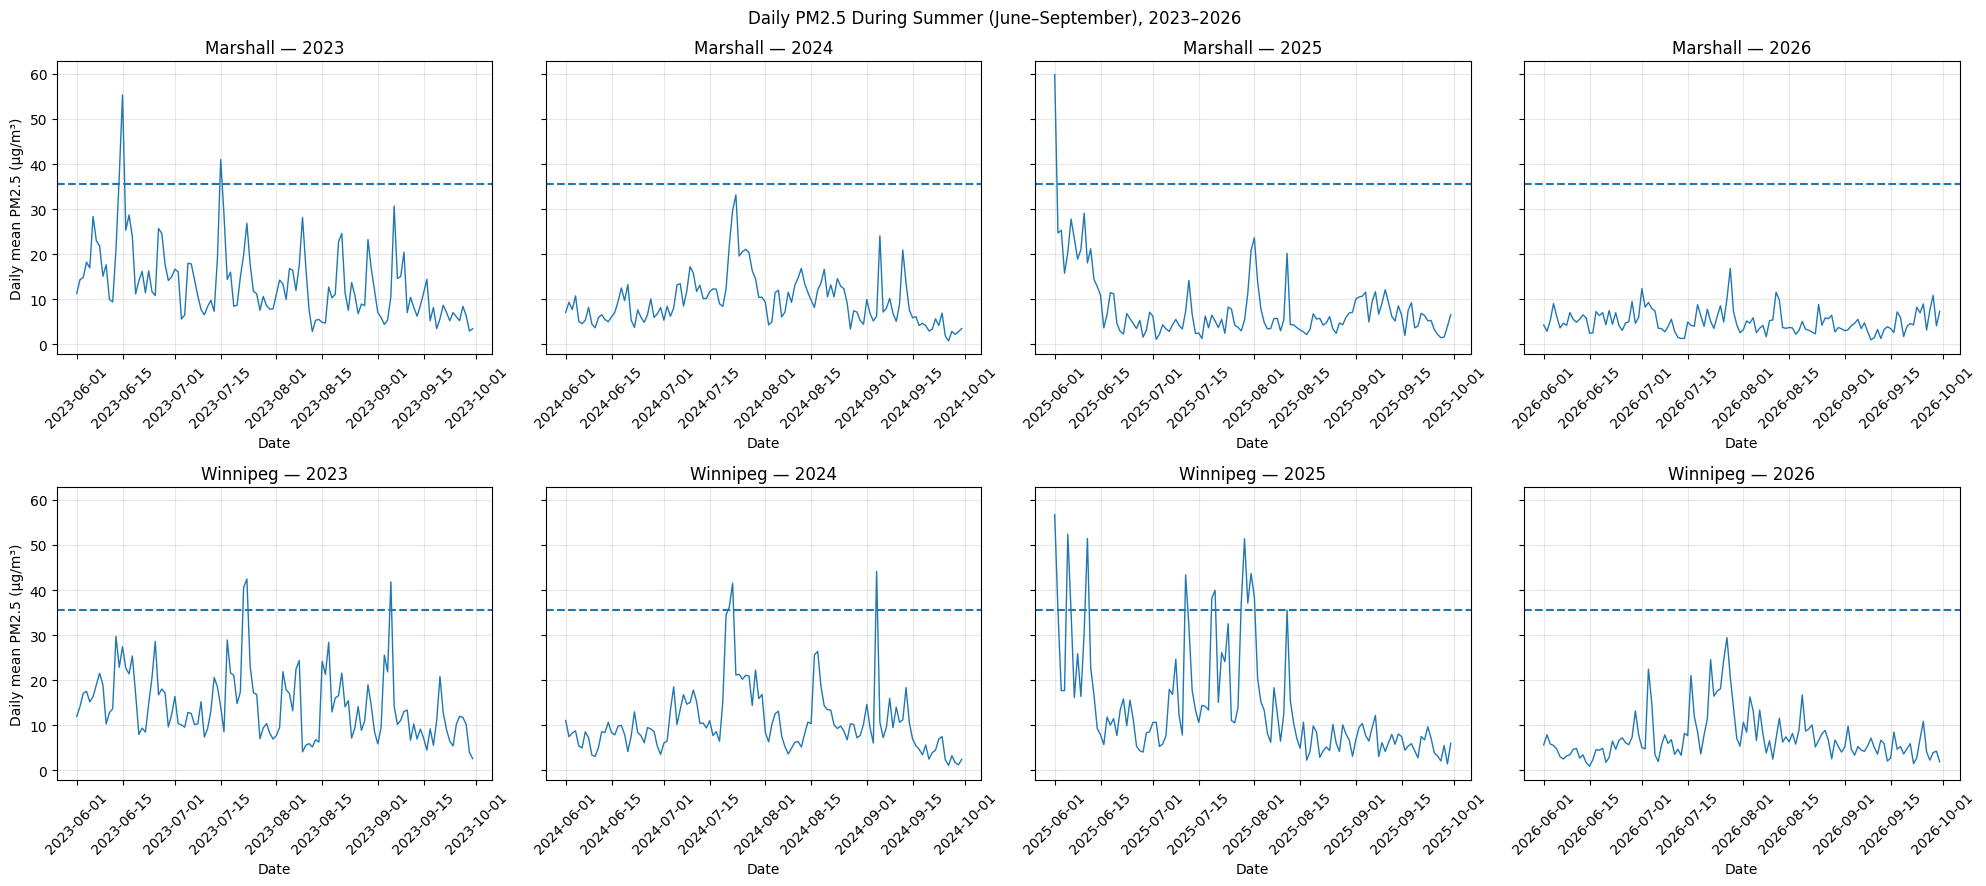

In [21]:
##Step 8.2: Plot Daily PM2.5 Trends
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(20, 9), sharey=True)

for ax, (city, year) in zip(
    axes.flat,
    sorted(clean_df.groupby(["city", "year"]).groups.keys())
):
    season = clean_df[
        (clean_df["city"] == city) &
        (clean_df["year"] == year)
    ].sort_values("date")

    ax.plot(
        season["date"],
        season["pm2_5_mean"],
        linewidth=1
    )

    ax.axhline(
        35.5,
        linestyle="--",
        label="High PM2.5 threshold"
    )

    ax.set_title(f"{city.title()} — {year}")
    ax.set_xlabel("Date")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True, alpha=0.3)

axes[0, 0].set_ylabel("Daily mean PM2.5 (µg/m³)")
axes[1, 0].set_ylabel("Daily mean PM2.5 (µg/m³)")

fig.suptitle("Daily PM2.5 During Summer (June–September), 2023–2026")
fig.tight_layout()
plt.show()

According to the charts, both Marshall and Winnipeg had their highest peaks during the summer of 2025, which well exceed the "High" threshold. Summer 2026 was also when PM2.5 levels never exceeded the threshold for both cities.

The bar chart below compares the number of High PM2.5 days in both cities throught the summers of 2023 to 2026. This provides a direct comparison for the elevated pollution. I expect Winnipeg to have the highest bar due having a the highest number of High days.

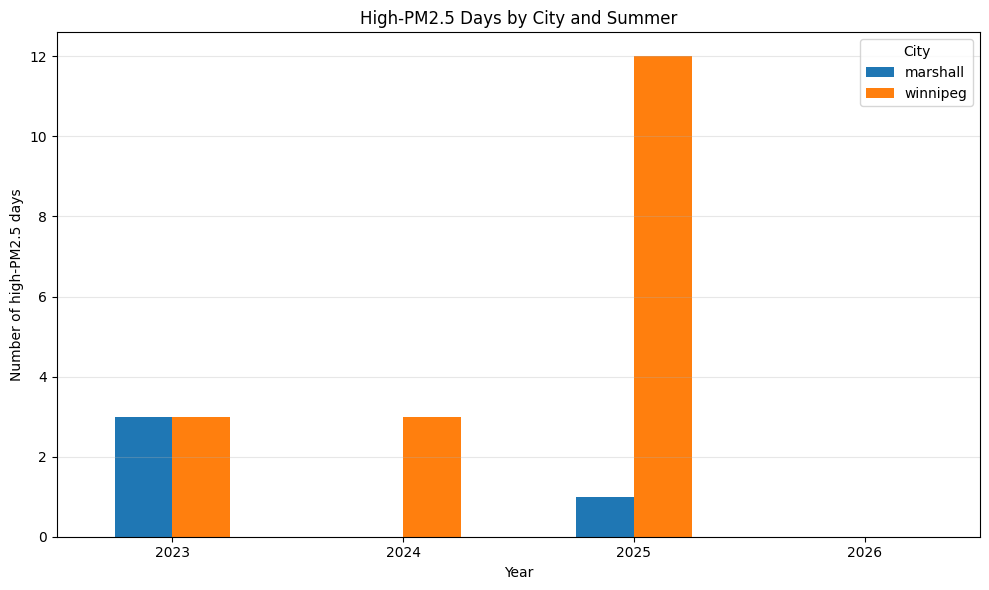

In [22]:
##Step 8.3: Plot High PM2.5 Days by City and Year
smoke_pivot = smoke_counts.pivot(
    index="year",
    columns="city",
    values="smoke_days"
).fillna(0)

ax = smoke_pivot.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_title("High-PM2.5 Days by City and Summer")
ax.set_xlabel("Year")
ax.set_ylabel("Number of high-PM2.5 days")
ax.legend(title="City")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Winniped had the most high days when compared to Marshall, having 12 in 2025 alone. This is while Marshall only had 3 High days at most during 2023 and 2025, and no High days during 2024 and 2026. This is consistent with the outputs from step 7.

An hourly heat map for the worst month will be created. The heatmap will use the original hourly PM2.5 measurements, since rows will represent the hours of the day. Shading will represent PM2.5 concentration, going from purple as the lowest to yellow as the highest.

,25
city,winnipeg
year,2025
month,7
smoke_days,7


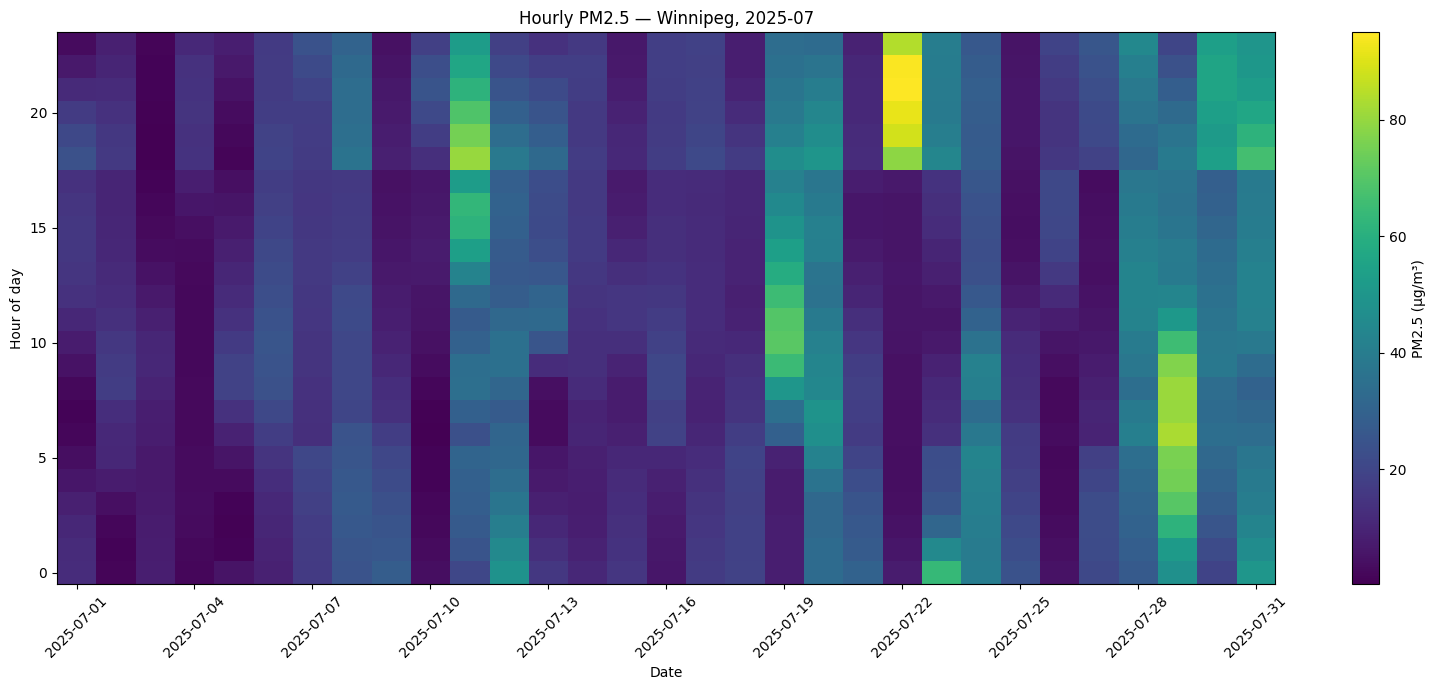

In [23]:
##Step 8.4: Hourly PM2.5 Heatmap for the Worst Month
# Find the city, year, and month with the most high-PM2.5 days
clean_df["month"] = clean_df["date"].dt.month

monthly_counts = (
    clean_df.groupby(["city", "year", "month"])["smoke_day"]
    .sum()
    .reset_index(name="smoke_days")
)

worst_month = monthly_counts.loc[
    monthly_counts["smoke_days"].idxmax()
]

display(worst_month)

# Load the original hourly data for that city and year
city = worst_month["city"]
year = int(worst_month["year"])
month = int(worst_month["month"])

air_file = raw_dir / f"{city}_air_quality_{year}.json"

with open(air_file, "r") as f:
    hourly_data = json.load(f)

hourly_df = pd.DataFrame(hourly_data["hourly"])
hourly_df["time"] = pd.to_datetime(hourly_df["time"])
hourly_df["date"] = hourly_df["time"].dt.date
hourly_df["hour"] = hourly_df["time"].dt.hour

# Keep only the selected month
month_df = hourly_df[
    hourly_df["time"].dt.month == month
].copy()

# Arrange measurements into a date-by-hour matrix
heatmap_data = month_df.pivot_table(
    index="hour",
    columns="date",
    values="pm2_5",
    aggfunc="mean"
)

# Plot the heatmap
fig, ax = plt.subplots(figsize=(16, 7))

image = ax.imshow(
    heatmap_data,
    aspect="auto",
    origin="lower"
)

ax.set_title(
    f"Hourly PM2.5 — {city.title()}, {year}-{month:02d}"
)
ax.set_xlabel("Date")
ax.set_ylabel("Hour of day")

# Display date labels at intervals
tick_positions = range(0, len(heatmap_data.columns), 3)
ax.set_xticks(list(tick_positions))
ax.set_xticklabels(
    [str(heatmap_data.columns[i]) for i in tick_positions],
    rotation=45
)

fig.colorbar(image, ax=ax, label="PM2.5 (µg/m³)")
plt.tight_layout()
plt.show()

The worst month was July 2025 in Winnipeg, MB, with the single worst day being the 22nd where PM2.5 levels were bright green to yellow in the last 6 hours of the day.

The cell below identifies the start and end dates for each consecutive High PM2.5 period. This further helps to distinguish isolated Highs from sustained pollution.

In [24]:
##Step 8.5: Identify Exact Dayes of Longest Consecutive High Days Episodes
def find_smoke_runs(group):
    group = group.sort_values("date").copy()

    is_smoke = group["smoke_day"].astype(bool)

    new_run = (
        is_smoke &
        (
            ~is_smoke.shift(fill_value=False) |
            group["date"].diff().dt.days.ne(1)
        )
    )

    group["run_id"] = new_run.cumsum()

    smoke = group[is_smoke]

    runs = (
        smoke.groupby("run_id")
        .agg(
            start_date=("date", "min"),
            end_date=("date", "max"),
            days=("date", "count"),
            max_pm25=("pm2_5_mean", "max")
        )
        .reset_index(drop=True)
    )

    return runs


all_runs = []

for (city, year), group in clean_df.groupby(["city", "year"]):
    runs = find_smoke_runs(group)

    if not runs.empty:
        runs["city"] = city
        runs["year"] = year
        all_runs.append(runs)

all_runs_df = pd.concat(all_runs, ignore_index=True)

all_runs_df = all_runs_df.sort_values(
    ["days", "max_pm25"],
    ascending=False
)

display(all_runs_df)

,start_date,end_date,days,max_pm25,city,year
12,2025-07-28,2025-08-01,5,51.395833,winnipeg,2025
0,2023-06-14,2023-06-15,2,55.337500,marshall,2023
3,2023-07-22,2023-07-23,2,42.450000,winnipeg,2023
5,2024-07-21,2024-07-22,2,41.508333,winnipeg,2024
11,2025-07-19,2025-07-20,2,39.941667,winnipeg,2025
2,2025-06-01,2025-06-01,1,59.841667,marshall,2025
7,2025-06-01,2025-06-01,1,56.720833,winnipeg,2025
8,2025-06-05,2025-06-05,1,52.370833,winnipeg,2025
9,2025-06-11,2025-06-11,1,51.433333,winnipeg,2025
6,2024-09-04,2024-09-04,1,44.125000,winnipeg,2024


The start and end date of Winnipeg's 5 day run, which is the longest out of the dataset, was from 2025-07-28 to	2025-08-01.

The cell below combines the number of high PM2.5 days, worst mean daily PM2.5, and longest consecutive runs to create a summary of each summer.

In [25]:
##Final Seasonal Summary
season_summary = (
    clean_df.groupby(["city", "year"])
    .agg(
        smoke_days=("smoke_day", "sum"),
        worst_pm25=("pm2_5_mean", "max"),
        average_pm25=("pm2_5_mean", "mean")
    )
    .reset_index()
)

season_summary = season_summary.merge(
    run_results,
    on=["city", "year"],
    how="left"
)

season_summary = season_summary.rename(
    columns={
        "worst_pm25": "worst_daily_pm25",
        "average_pm25": "season_average_pm25"
    }
)

display(season_summary.round(2))

,city,year,smoke_days,worst_daily_pm25,season_average_pm25,longest_smoke_run
0,marshall,2023,3,55.34,13.61,2
1,marshall,2024,0,33.16,9.58,0
2,marshall,2025,1,59.84,8.07,1
3,marshall,2026,0,16.85,5.08,0
4,winnipeg,2023,3,42.45,14.56,2
5,winnipeg,2024,3,44.12,10.80,2
6,winnipeg,2025,12,56.72,14.16,5
7,winnipeg,2026,0,29.45,7.30,0


Winnipeg during summer 2025 had the most total smoke days, 12, and the longest consecutive smoke days run, 5.

## Conclusions

This project investigated high-PM2.5 days and their relationship with weather conditions in Marshall, Minnesota, and Winnipeg, Manitoba, from June through September of 2023 through 2026.

The analysis identified 22 high-PM2.5 days across both cities using a daily mean PM2.5 threshold of 35.5 µg/m³. Winnipeg recorded 18 high-PM2.5 days, while Marshall recorded 4. Winnipeg experienced high-PM2.5 days during 2023, 2024, and 2025, while Marshall experienced them during 2023 and 2025. Neither city recorded any high-PM2.5 days during the 2026 summer.

Summer 2025 had the most significant high-PM2.5 activity. Winnipeg recorded 12 high-PM2.5 days, compared with only one in Marshall. Winnipeg's longest consecutive high-PM2.5 episode occurred from July 28 through August 1, 2025, lasting five days. The highest daily mean PM2.5 concentration in Marshall was 59.84 µg/m³ on June 1, 2025, while Winnipeg reached 56.72 µg/m³ on the same date.

The weather comparison showed that high-PM2.5 days had an average precipitation of 2.05 mm and an average maximum wind speed of 16.05 km/h. Other days had higher averages of 2.99 mm of precipitation and 19.32 km/h of maximum wind speed. Average maximum temperatures were nearly identical, at 25.04°C on high-PM2.5 days and 25.28°C on other days. These results suggest that elevated PM2.5 concentrations were associated with lower precipitation and lower wind speeds in this dataset.

Overall, the results show that Winnipeg experienced more frequent and sustained periods of elevated PM2.5 than Marshall during the study period, particularly in 2025. However, high PM2.5 concentrations do not necessarily indicate wildfire smoke, and the analysis does not establish that weather conditions caused the observed differences.

## Limitations

Several limitations should be considered when interpreting the results:

1. **Limited geographic coverage:** The analysis uses data for only two locations: Marshall, Minnesota, and Winnipeg, Manitoba. Results may not represent conditions throughout Minnesota, Manitoba, or other regions.

2. **Modeled air-quality data:** Air-quality estimates were obtained through Open-Meteo and are based on atmospheric modeling rather than direct measurements from local air-quality monitoring stations. The estimates may differ from actual conditions experienced at specific locations.

3. **Spatial resolution:** The air-quality model represents an approximately 45 km grid. This means the data may not capture localized differences in pollution within either city.

4. **Identifying wildfire smoke:** PM2.5 can originate from sources other than wildfires, including transportation, industry, and other combustion sources. The 35.5 µg/m³ threshold identifies days with elevated particulate concentrations but does not independently confirm that wildfire smoke caused them.

5. **Limited weather variables:** The analysis includes precipitation, maximum temperature, maximum wind speed, and dominant wind direction. Other factors, such as atmospheric stability, humidity, regional wildfire activity, and air-mass movement, may also influence PM2.5 concentrations.

6. **Limited seasonal coverage:** The analysis only examines June through September from 2023 through 2026. It does not include the entire year or capture potential high-PM2.5 events outside the selected months.

7. **Association does not establish causation:** The observed differences in precipitation and wind speed between high-PM2.5 days and other days do not prove that weather conditions caused changes in particulate concentrations.

8. **Daily aggregation:** Hourly air-quality measurements were converted into daily averages and maximum values. This simplifies comparisons but may hide short periods of unusually high or low concentrations within individual days.

## Data Sources and Attribution

This project used two public data sources:

**1. Open-Meteo Air Quality API**

- Website: https://open-meteo.com/en/docs/air-quality-api
- Used to retrieve hourly PM2.5 concentrations, US AQI values, PM2.5-specific US AQI values, and aerosol optical depth estimates.
- Data was collected for Marshall, Minnesota, and Winnipeg, Manitoba, from June 1 through September 30 for each year from 2023 through 2026.
- Hourly measurements were aggregated into daily mean PM2.5, maximum AQI, and mean aerosol optical depth.

**2. Open-Meteo Historical Weather API**

- Website: https://open-meteo.com/en/docs/historical-weather-api
- Used to retrieve daily precipitation, maximum temperature, maximum wind speed, and dominant wind direction.
- Daily weather observations were combined with the aggregated air-quality data to examine potential relationships between weather conditions and PM2.5 concentrations.

**Tools and libraries used:**

- Python
- Requests for API communication
- Pandas for data manipulation, aggregation, and cleaning
- NumPy for numerical operations
- Matplotlib for data visualization
- SQLite for database storage and SQL queries
- JSON for storing the original API responses

The data was retrieved from publicly accessible sources and processed for educational and analytical purposes. The original API responses were preserved in the `data/raw/` directory, while the cleaned daily dataset was saved as a CSV file and SQLite database in `data/clean/`.

## AI Use Note

I used ChatGPT to help understand the assignment, troubleshoot Python code, and organize parts of the data analysis. I ran the code in Google Colab and used the results from my own datasets to interpret the findings and develop the project's conclusions.